In [86]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import lattice
import importlib
import kmc
import loading as ld
importlib.reload(kmc)

<module 'kmc' from '/home/nara/Projetos/programa-tiago/kmc.py'>

In [87]:
RF=1
tau = 1
r0=1
n= 500 
LOAD_FIXED_KAPPA= False
FIXED_KAPPA = 0.476#2/3
save = False
cutoff = r0
krot_dip = 0 #=0 -> no rotation
nrounds =10000

In [88]:
import shutil
import os
pasta = 'Rounds'
try: 
    shutil.rmtree(pasta)
except:
    pass

os.makedirs(pasta)

M = 10
nrounds = 5000

In [ ]:
#hm = os.getwdc()
#os.system(f"cd {hm}; rm *.txt")

#3D 

n = 8
L =  r0*np.array([n,n,n])
PBC = [0,1,2]

kappas2_LD = []
for i in range(M):
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=10,verbose=2)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

    kappas2 = out_dict['kappa2_D_lis']

    kappas2_LD = [np.mean(kappas2[0:m]) for m in range(5,nrounds)]
    c_3D = np.array(kappas2_LD)
    np.savetxt(f"{pasta}/kappas2_rounds_3D_{i}.txt", c_3D)


In [ ]:
#2D
n = 25
L =  r0*np.array([n,n])
PBC = [0,1]


kappas2_LD = []
for i in range(M):
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=10,verbose=2)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

    kappas2 = out_dict['kappa2_D_lis']

    kappas2_LD = [np.mean(kappas2[0:m]) for m in range(5,nrounds)]
    c_2D = np.array(kappas2_LD)
    np.savetxt(f"{pasta}/kappas2_rounds_2D_{i}.txt", c_2D)


In [ ]:
#1D

n = 500
L =  r0*np.array([n])
PBC = [0]

kappas2_LD = []
for i in range(M):
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=10,verbose=10)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

    kappas2 = out_dict['kappa2_D_lis']

    kappas2_LD = [np.mean(kappas2[0:m]) for m in range(5,nrounds)]
    c_1D = np.array(kappas2_LD)
    np.savetxt(f"{pasta}/kappas2_rounds_1D_{i}.txt", c_1D)



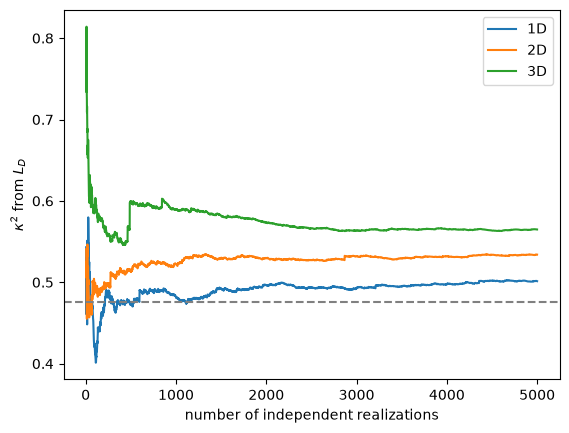

In [92]:
c_1D = np.zeros(nrounds-5)
c_2D = np.zeros(nrounds-5)
c_3D = np.zeros(nrounds-5)
nround_lis = np.arange(5, nrounds)


for i in range(M):
    c_1D += np.loadtxt(f"{pasta}/kappas2_rounds_1D_{i}.txt")
    c_2D += np.loadtxt(f"{pasta}/kappas2_rounds_2D_{i}.txt")
    c_3D += np.loadtxt(f"{pasta}/kappas2_rounds_3D_{i}.txt")
    #c_3D_i = np.loadtxt(f"{pasta}/kappas2_rounds_3D_{i}.txt")
    #plt.plot(nround_lis_3D, c_3D_i)

c_1D = c_1D/M
c_2D = c_2D/M
c_3D = c_3D/M

plt.figure()
plt.plot(nround_lis, c_1D, label = '1D')
plt.plot(nround_lis, c_2D, label = '2D')
plt.plot(nround_lis, c_3D, label = '3D')
plt.axhline(0.476, linestyle = '--', c = 'gray')
plt.xlabel("number of independent realizations")
plt.ylabel(r"$\kappa^2$ from $L_D$")
plt.legend()
plt.show()


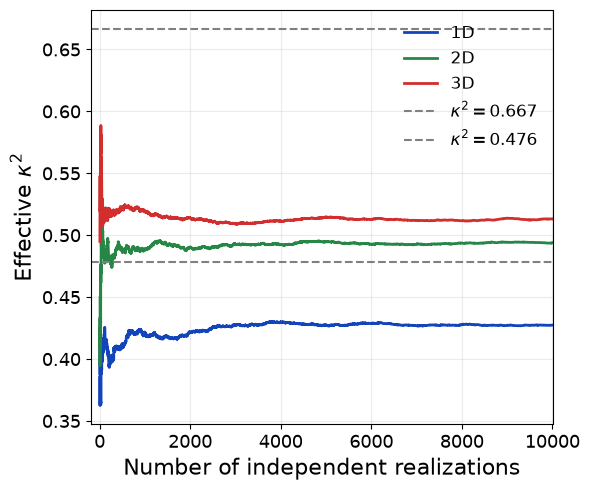

In [77]:
import numpy as np
import matplotlib.pyplot as plt

# Dados
#c_1D = np.loadtxt("kappas2_rounds_1D.txt")
#c_2D = np.loadtxt("kappas2_rounds_2D.txt")
#c_3D = np.loadtxt("kappas2_rounds_3D.txt")

xlim = (-200,nrounds)

# Eixo x
nround_lis = np.arange(5, nrounds)

# Figura
fig, ax = plt.subplots(figsize=(6, 5))

# Curvas
ax.plot(nround_lis, c_1D,label="1D",linewidth=2, c = "#1345BA")

ax.plot(nround_lis, c_2D,label="2D",linewidth=2, c = "#268646")

ax.plot(nround_lis, c_3D,label="3D",linewidth=2, c = "#D22E2E")

# Linha de referência
ax.axhline(2/3,linestyle="--",linewidth=1.5,label=r"$\kappa^2= 0.667$", c = "gray")

ax.axhline(0.478,linestyle="--",linewidth=1.5,label=r"$\kappa^2=0.476$", c = "gray")

# Eixos
ax.set_xlabel("Number of independent realizations", fontsize=16)
ax.set_ylabel(r"Effective $\kappa^2$", fontsize=16)


# Escala dos números
ax.tick_params(axis="both", labelsize=13)

# Grade
ax.grid(True, alpha=0.25)

# Legenda
ax.legend(fontsize=12, frameon=False)

# Limites
ax.set_xlim(*xlim)

# Ajuste
fig.tight_layout()

# Salvar

fig.savefig(
    "kappa2_rounds.png",
    dpi=500,
    bbox_inches="tight")

plt.show()

In [ ]:
# 1D mais redes

n = 20
L =  r0*np.array([n])
PBC = [0]

kappas2_LD = []

syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice()
results = Parallel(n_jobs=10,verbose=10)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

kappas2 = out_dict['kappa_LD_lis']

kappas2_LD = [np.mean(kappas2[0:n]) for n in range(2,nrounds)]

c_1D_1 = np.array(kappas2_LD)
##########
yst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice()
results = Parallel(n_jobs=10,verbose=10)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

kappas2 = out_dict['kappa_LD_lis']

kappas2_LD = [np.mean(kappas2[0:n]) for n in range(2,nrounds)]

c_1D_2 = np.array(kappas2_LD)
#########
yst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice()
results = Parallel(n_jobs=10,verbose=10)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

kappas2 = out_dict['kappa_LD_lis']

kappas2_LD = [np.mean(kappas2[0:n]) for n in range(2,nrounds)]

c_1D_3 = np.array(kappas2_LD)
###########

nround_lis = np.arange(len(c_1D_1))
plt.figure()
plt.plot(nround_lis, c_1D_1)
plt.plot(nround_lis, c_1D_2)
plt.plot(nround_lis, c_1D_3)
plt.xlabel("N rounds")
plt.ylabel("kappa² do LD")
plt.show()